In [1]:
!nvidia-smi

Sun Nov  1 12:41:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
!unzip -q project-1-at-2026-11-01-20-55-4bc047bc.zip -d /content/custom_data

In [15]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py


!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

--2026-11-01 13:01:17--  https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3203 (3.1K) [text/plain]
Saving to: ‘/content/train_val_split.py’

/content/train_val_ 100%[===================>]   3.13K  --.-KB/s    in 0s      

2026-11-01 13:01:17 (41.5 MB/s) - ‘/content/train_val_split.py’ saved [3203/3203]

Created folder at /content/data/train/images.
Created folder at /content/data/train/labels.
Created folder at /content/data/validation/images.
Created folder at /content/data/validation/labels.
Number of image files: 76
Number of annotation files: 76
Images moving to train: 68
Images moving to validation: 8


In [16]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [17]:
import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):


  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)


  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }


  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Created config file at {path_to_data_yaml}')

  return


path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nFile contents:\n')
!cat /content/data.yaml

Created config file at /content/data.yaml

File contents:

path: /content/data
train: train/images
val: validation/images
nc: 3
names:
- Mouse
- Pen
- Perfume


In [18]:
!yolo detect train data=/content/data.yaml model=yolo11s.pt epochs=60 imgsz=640

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None,

In [19]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs

image 1/8 /content/data/validation/images/83c49c3c-IMG_2415.jpg: 640x480 3 Pens, 2 Perfumes, 19.3ms
image 2/8 /content/data/validation/images/8479ca43-IMG_2417.jpg: 640x480 3 Perfumes, 19.2ms
image 3/8 /content/data/validation/images/95adfa7d-IMG_2408.jpg: 640x480 (no detections), 19.2ms
image 4/8 /content/data/validation/images/aafb90a2-IMG_2400.jpg: 640x480 1 Pen, 19.2ms
image 5/8 /content/data/validation/images/ac7a9b24-IMG_2370.jpg: 640x480 1 Mouse, 1 Perfume, 19.2ms
image 6/8 /content/data/validation/images/c2e23b42-IMG_2358.jpg: 640x480 2 Mouses, 19.2ms
image 7/8 /content/data/validation/images/ca459f73-IMG_2403.jpg: 640x480 2 Pens, 19.2ms
image 8/8 /content/data/validation/images/ff2a6a55-IMG_2386.jpg: 640x480 1 Pen, 19.3ms
Speed: 9.1ms preprocess, 19.2ms inference, 4.1ms postprocess per image at shape (1, 3, 640

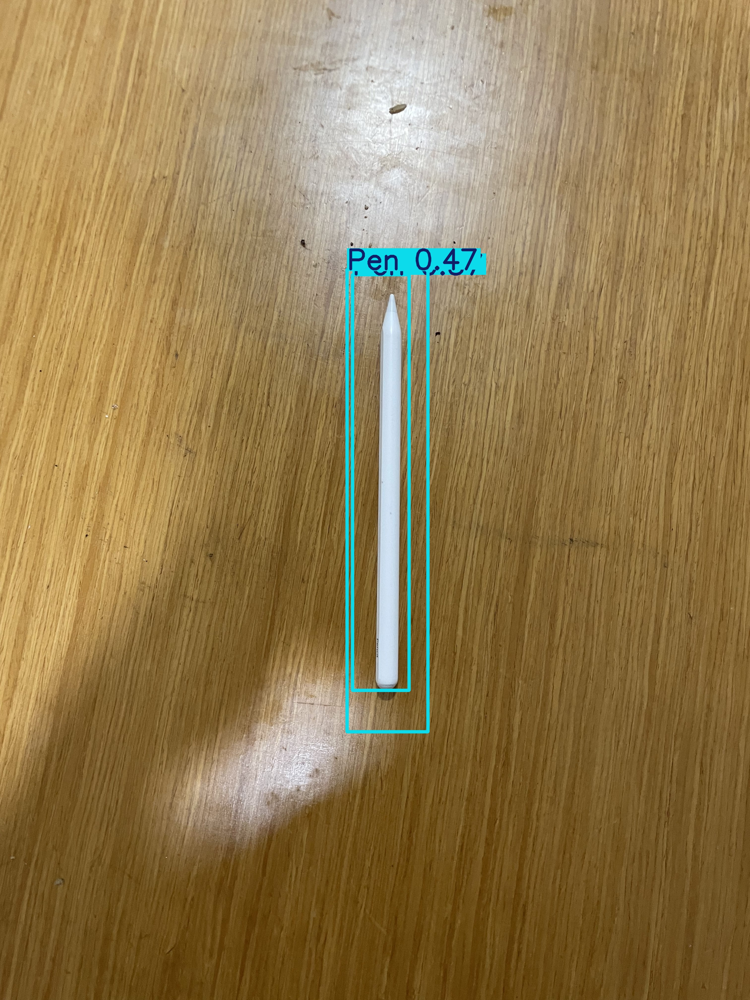

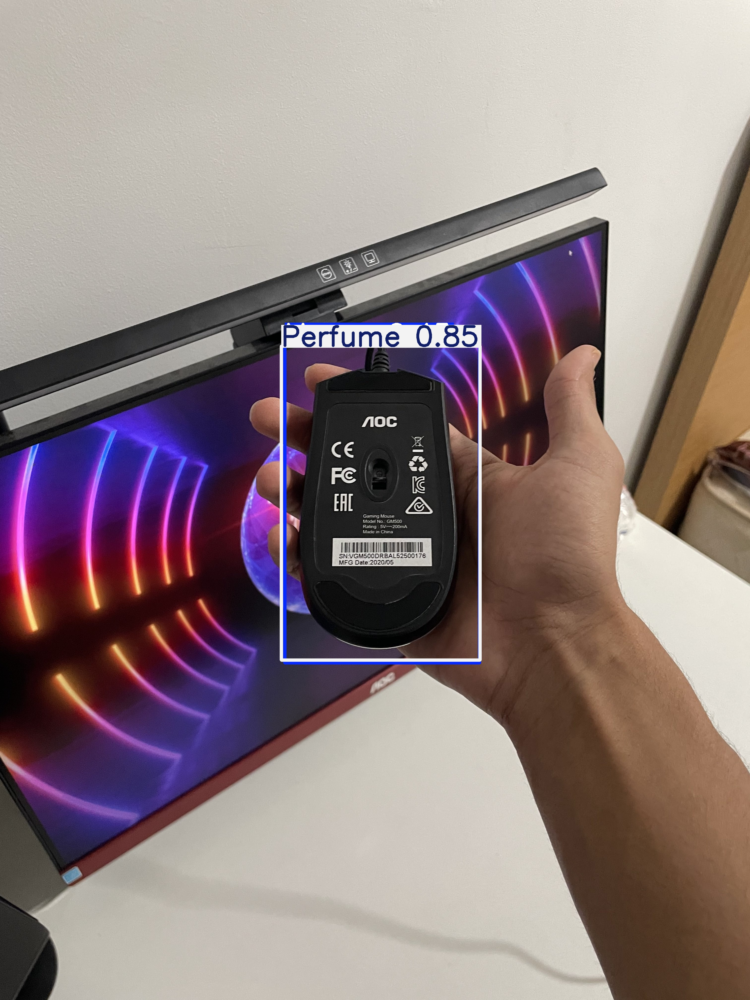

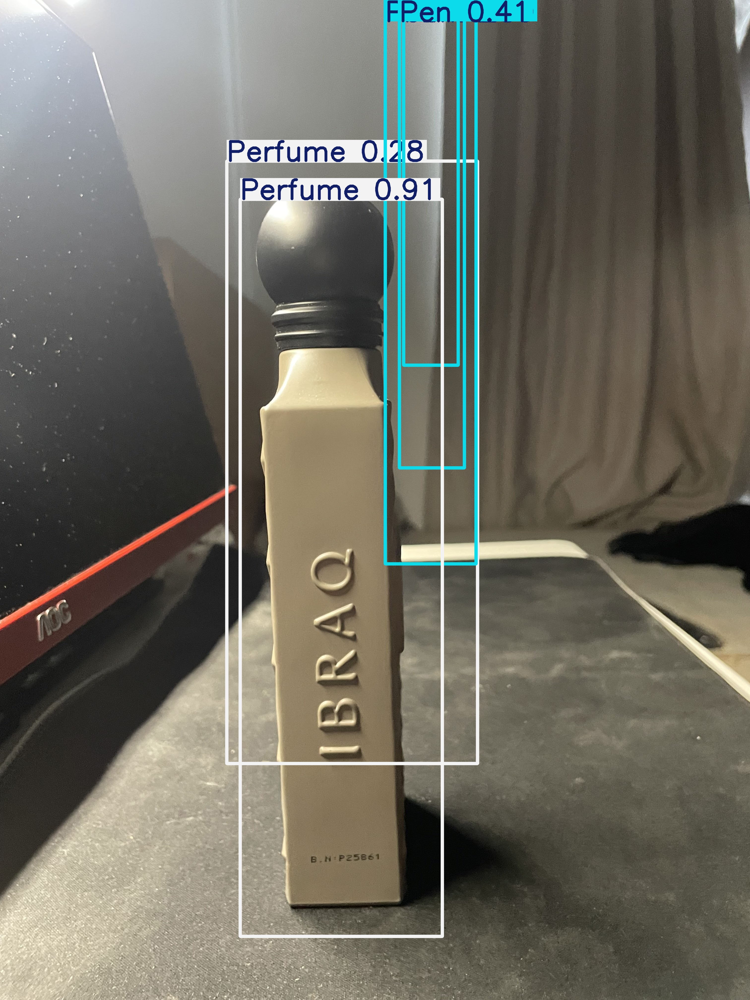

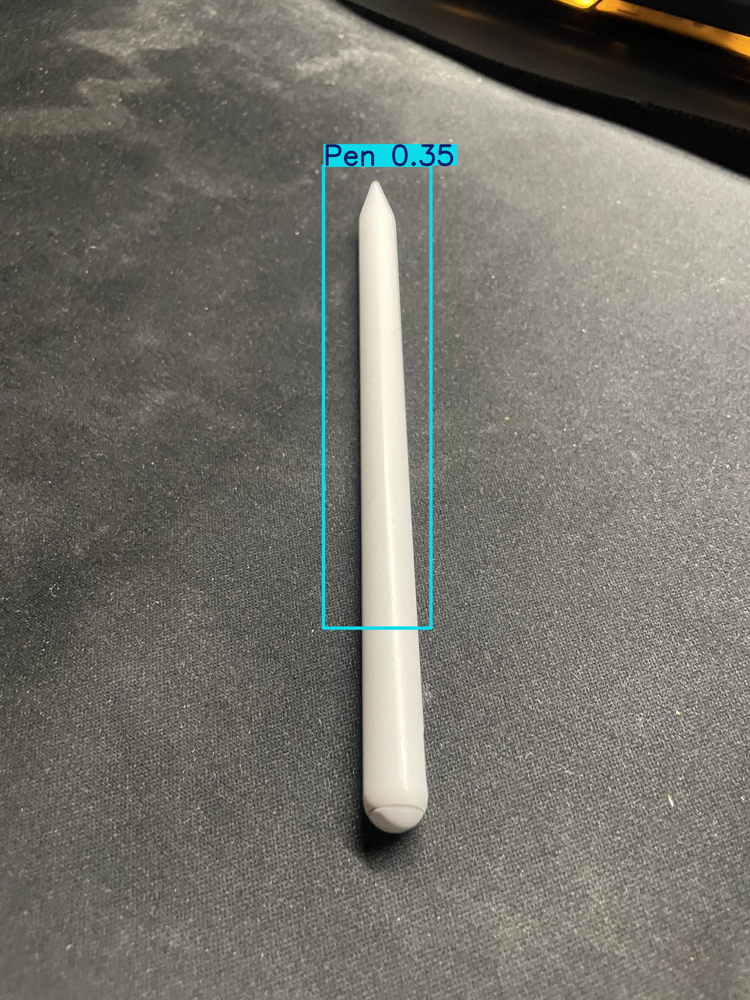

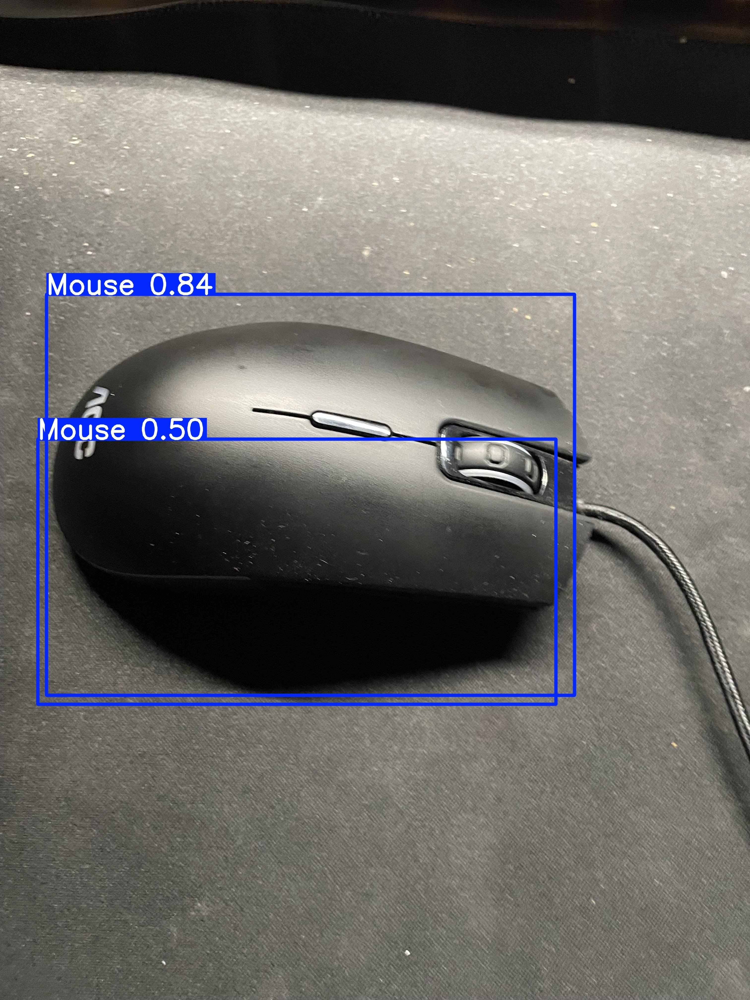

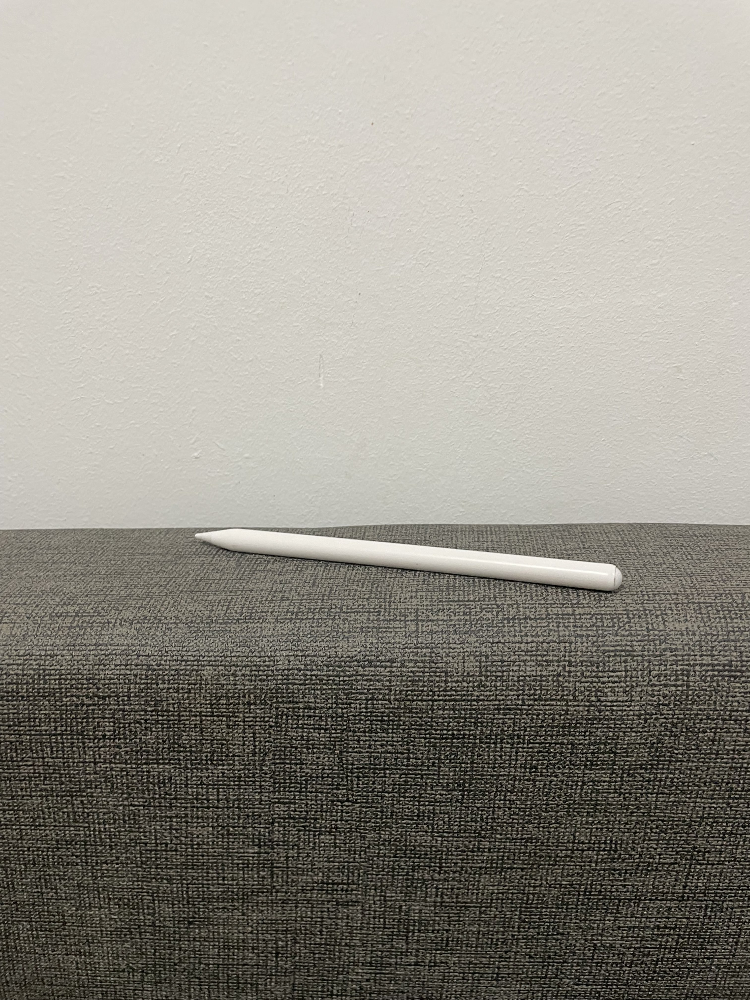

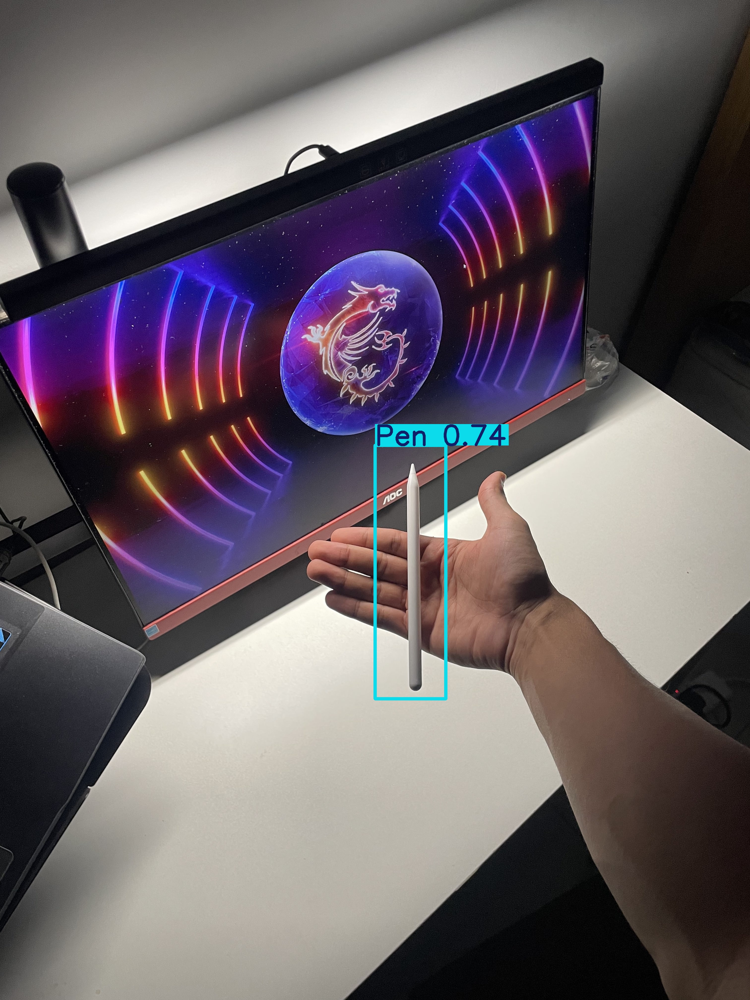

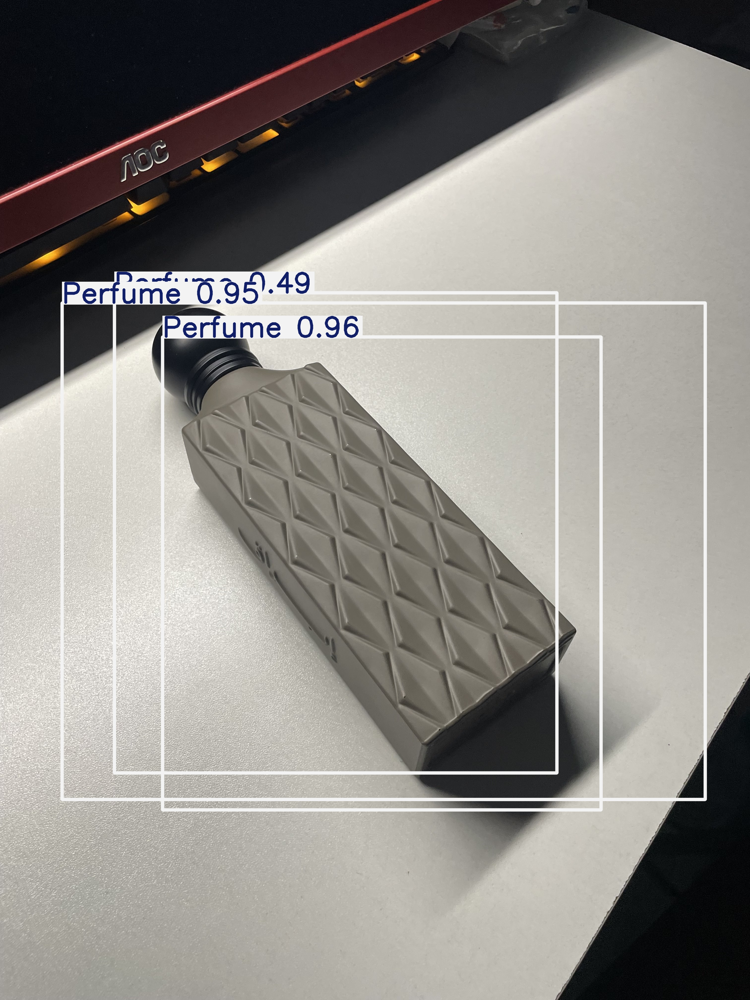

In [20]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')


In [21]:

!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

/content/my_model
  adding: my_model.pt (deflated 9%)
  adding: train/ (stored 0%)
  adding: train/train_batch1.jpg (deflated 5%)
  adding: train/train_batch250.jpg (deflated 12%)
  adding: train/BoxF1_curve.png (deflated 8%)
  adding: train/val_batch0_labels.jpg (deflated 9%)
  adding: train/args.yaml (deflated 53%)
  adding: train/train_batch2.jpg (deflated 4%)
  adding: train/labels.jpg (deflated 34%)
  adding: train/confusion_matrix_normalized.png (deflated 31%)
  adding: train/train_batch252.jpg (deflated 16%)
  adding: train/weights/ (stored 0%)
  adding: train/weights/best.pt (deflated 9%)
  adding: train/weights/last.pt (deflated 9%)
  adding: train/train_batch0.jpg (deflated 4%)
  adding: train/BoxPR_curve.png (deflated 25%)
  adding: train/results.csv (deflated 60%)
  adding: train/results.png (deflated 6%)
  adding: train/train_batch251.jpg (deflated 14%)
  adding: train/val_batch0_pred.jpg (deflated 9%)
  adding: train/BoxP_curve.png (deflated 12%)
  adding: train/BoxR_curv